              Q01         Q02         Q03         Q04
count  288.000000  288.000000  288.000000  288.000000
mean     5.051736    3.599375    4.927500    5.220833
std      1.005790    1.098847    0.862153    1.193909
min      3.330000    0.610000    1.180000    1.600000
25%      4.130000    3.487500    4.970000    4.100000
50%      4.910000    3.970000    5.090000    4.900000
75%      6.000000    4.350000    5.380000    6.300000
max      8.500000    4.720000    6.000000    7.500000


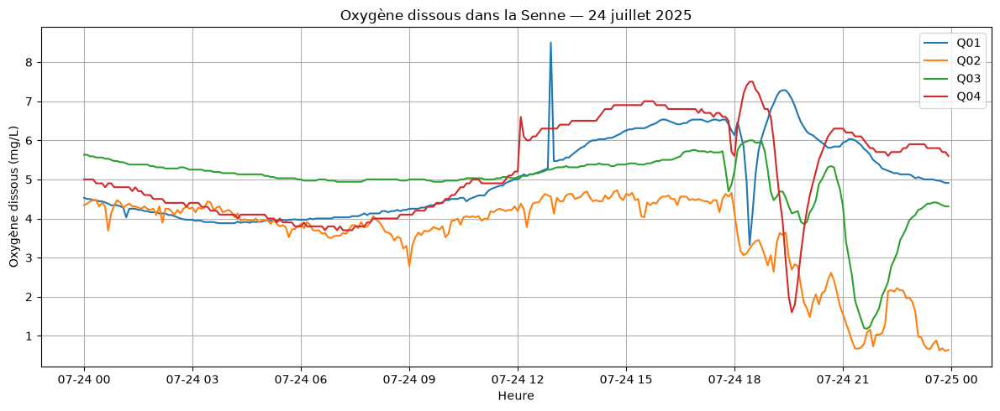

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Charger le même fichier que pour la pluie
df = pd.read_csv(
    "../data/24_juillet_2025_donnees_preparees.csv"
)

# Convertir les dates
df["date"] = pd.to_datetime(
    df["Date/heure locale (UTC+2)"]
)

# Les quatre stations d'oxygène
stations = ["Q01", "Q02", "Q03", "Q04"]

# Afficher leurs concentrations
print(df[stations].describe())

# Dessiner les quatre courbes
plt.figure(figsize=(12, 5))

for station in stations:
    plt.plot(df["date"], df[station], label=station)

plt.title("Oxygène dissous dans la Senne — 24 juillet 2025")
plt.xlabel("Heure")
plt.ylabel("Oxygène dissous (mg/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Préparer les données
Dans le code si en bas on as 10.0 : c'est une référence provisoire de normalisation commune aux quatre stations. Elle sera gardé identique entre stations et entre événements, sauf justification explicite d'un changement.

In [15]:
import numpy as np

stations = ["Q01", "Q02", "Q03", "Q04"]

# Même chronologie pour les quatre stations
temps = np.linspace(0, 1, len(df))

# Échelle commune : 0 à 10 mg/L
reference_oxygene = 10.0

# Préparer une série normalisée par station
oxygene_normalise = {}

for station in stations:
    valeurs = df[station].to_numpy(dtype=float)

    oxygene_normalise[station] = np.clip(
        valeurs / reference_oxygene,
        0,
        1
    )

Sonifier les quatre stations avec STRAUSS

In [20]:
from strauss.sonification import Sonification
from strauss.sources import Objects
from strauss.score import Score
from strauss.generator import Synthesizer

duree = 60
sons_oxygene = {}

positions = {
    "Q01": 0.25,
    "Q02": 0.42,
    "Q03": 0.58,
    "Q04": 0.75
}

for station in stations:

    data_son = {
        "pitch": 1.0,
        "time_evo": temps,
        "pitch_shift": oxygene_normalise[station],
        "volume": 0.35,
        "azimuth": positions[station],
        "polar": 0.5
    }

    sources = Objects(data_son.keys())
    sources.fromdict(data_son)
    sources.apply_mapping_functions()

    generator = Synthesizer()
    generator.load_preset("pitch_mapper")

    score = Score([["A2"]], duree)

    soni = Sonification(
        score,
        sources,
        generator,
        "stereo"
    )

    soni.render()

    sons_oxygene[station] = soni

    print("Sonification terminée :", station)

Sonification terminée : Q01
Sonification terminée : Q02
Sonification terminée : Q03
Sonification terminée : Q04


Écouter les stations individuellement

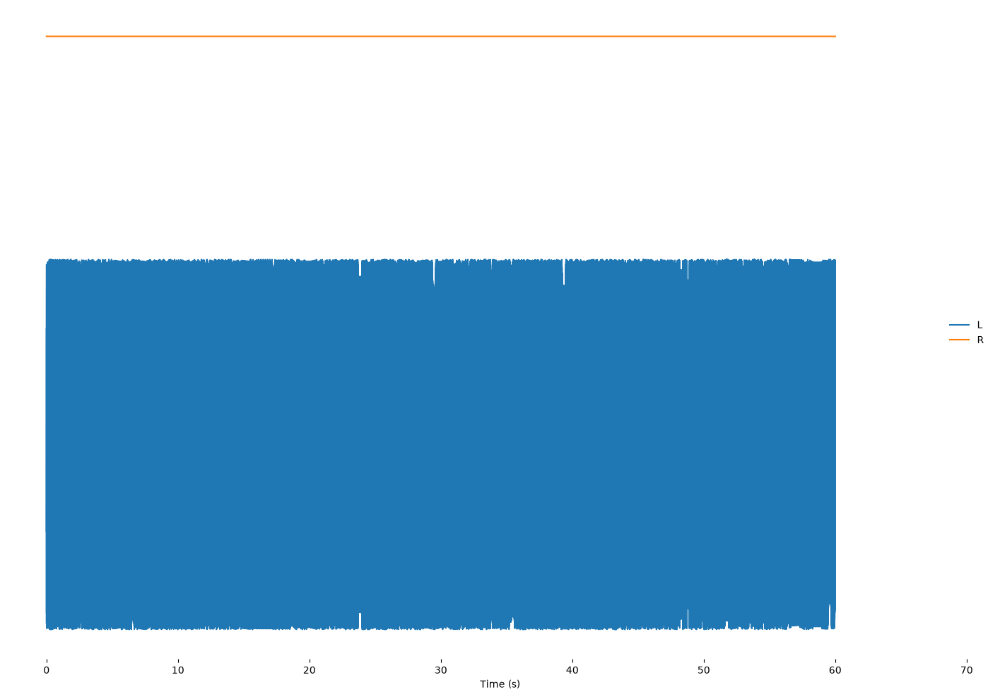

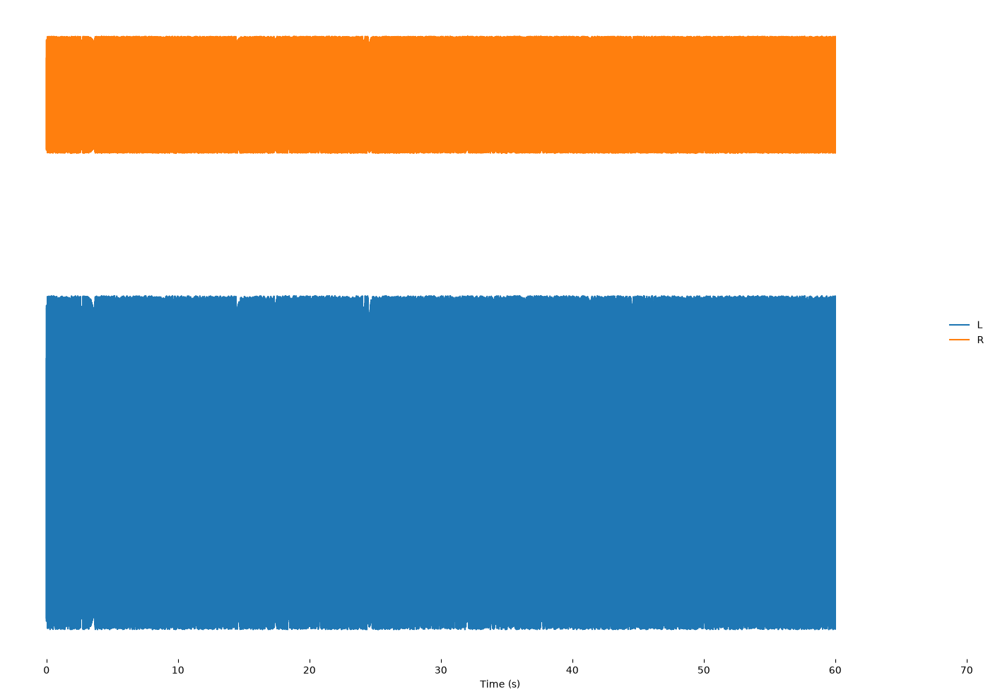

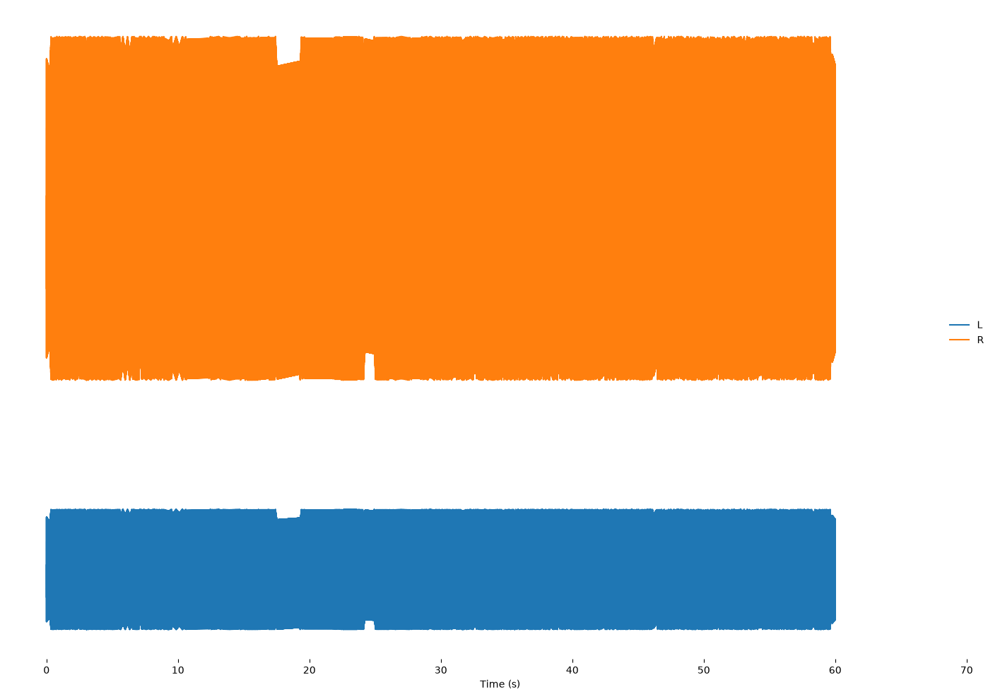

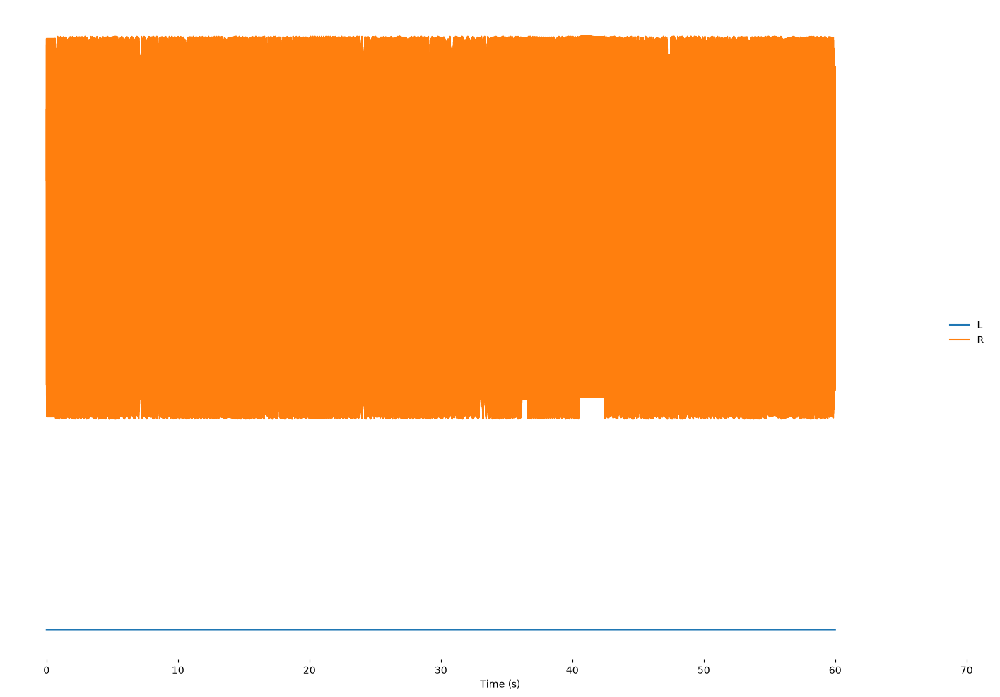

In [21]:
# Écouter Q01
sons_oxygene["Q01"].notebook_display()
# Écouter Q02
sons_oxygene["Q02"].notebook_display()
# Écouter Q03
sons_oxygene["Q03"].notebook_display()
# Écouter Q04
sons_oxygene["Q04"].notebook_display()

Pour les écouter toutes ensmeble

In [28]:
import numpy as np
from IPython.display import Audio, display

pistes = []
frequence = None

for station in stations:

    # Récupérer les canaux audio de la station
    sorties = sons_oxygene[station].out_channels

    # Chaque canal est un objet Stream
    canaux = []

    for stream in sorties.values():

        audio = np.asarray(stream.samples, dtype=float)
        canaux.append(audio)

        if frequence is None:
            frequence = stream.samprate
        elif stream.samprate != frequence:
            raise ValueError("Fréquences d'échantillonnage différentes")

    # Regrouper les canaux de cette station
    piste = np.stack(canaux, axis=0)
    pistes.append(piste)

# Vérifier que toutes les pistes ont la même taille
assert all(p.shape == pistes[0].shape for p in pistes)

# Mélanger les quatre stations
mix = sum(pistes) / len(pistes)

# Écouter le résultat sans créer de WAV
display(Audio(mix, rate=int(frequence), normalize=True))

Á verifier apres ecoute: 
1. Entends-tu plusieurs sons distincts ou un seul son difficile à comprendre ?
2. Peux-tu percevoir les fortes baisses d'oxygène en soirée ?
3. La spatialisation gauche-droite aide-t-elle réellement à distinguer les stations ?

In [23]:
stream = sons_oxygene["Q01"].out_channels

print(type(stream))
print(type(next(iter(stream.values()))))
print(dir(next(iter(stream.values()))))

<class 'dict'>
<class 'strauss.stream.Stream'>
['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_bvalues', '_nsamp_stream', '_nyqfrq', 'bufferize', 'consolidate_buffers', 'filt_sweep', 'get_sampfracs', 'length', 'reset', 'samples', 'samprate', 'samptime', 'save_wav', 'values']
